<a href="https://colab.research.google.com/github/nageshnnazare/pytorch-expts/blob/main/7_Fashion_MNIST_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Load dataset
import torchvision
import torchvision.transforms as T
from torch.utils.data import DataLoader

transform = T.Compose([T.ToTensor()])

train_ds = torchvision.datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_ds = torchvision.datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=64, shuffle=False, pin_memory=True)

print(f"Train size : {len(train_ds)}")
print(f"Test size  : {len(test_ds)}")
print(f"Classes    : {len(train_ds.classes)}")
print(train_ds.classes)

Train size : 60000
Test size  : 10000
Classes    : 10
['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


In [ ]:
import torch
torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


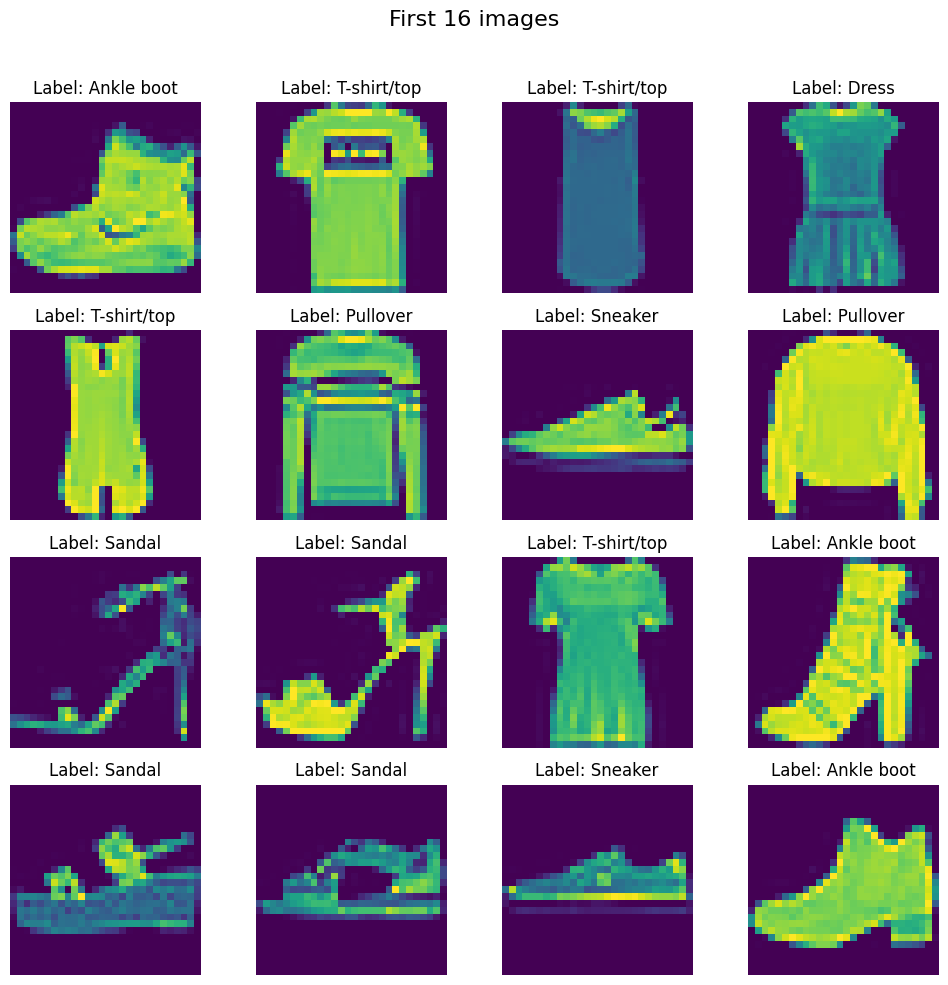

In [ ]:
import matplotlib.pyplot as plt

# Visualize
n, m = 4, 4
fig, axes = plt.subplots(nrows=n, ncols=m, figsize=(10,10))
fig.suptitle(f"First {n*m} images", fontsize=16)

for i, ax in enumerate(axes.flat):
  img, label = train_ds[i]
  ax.imshow(img.squeeze())
  ax.axis('off')
  ax.set_title(f"Label: {train_ds.classes[label]}")

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [ ]:
from torch.nn.modules.linear import Linear
import torch.nn as nn

# Parameters
learning_rate = 0.1
epochs = 101
lambdaf = 1e-4

# Define NN
class NeuralNetwork(nn.Module):
  def __init__(self, input_features):
    super().__init__()
    self.features = nn.Sequential(
        # (1, 28, 28) -> (32, 28, 28)
        nn.Conv2d(input_features, 32,
                  kernel_size=3, padding='same'),
        nn.ReLU(),
        nn.BatchNorm2d(32),
        # (32, 28, 28) -> (32, 14, 14)
        nn.MaxPool2d(kernel_size=2, stride=2),

        # (32, 14, 14) -> (64, 14, 14)
        nn.Conv2d(32, 64,
                  kernel_size=3, padding='same'),
        nn.BatchNorm2d(64),
        nn.ReLU(),
        # (64, 14, 14) -> (64, 7, 7)
        nn.MaxPool2d(kernel_size=2, stride=2),
    )
    self.classifier = nn.Sequential(
        nn.Flatten(),
        nn.Linear(64 * 7 * 7, 128),
        nn.ReLU(),
        nn.Dropout(p=0.4),

        nn.Linear(128, 64),
        nn.ReLU(),
        nn.Dropout(p=0.4),

        nn.Linear(64, 10),
    )
    self.optim = torch.optim.SGD(self.parameters(),
                                 lr=learning_rate,
                                 weight_decay=lambdaf)
    self.loss_fn = nn.CrossEntropyLoss()

  def __print__(self):
    print()

  def forward(self, x):
    x = self.features(x)
    x = self.classifier(x)
    return x

  def loss(self, y_pred, y):
    return self.loss_fn(y_pred, y)

  def backward(self, loss):
    self.optim.zero_grad()
    loss.backward()
    self.optim.step()

In [ ]:
# Create Model
model = NeuralNetwork(1)
model = model.to(device)
print(model)
print(f"Batches : {len(train_loader)}")

# Training loop
for epoch in range(epochs):
    total_epoch_loss = 0
    for bfeatures, blabels in train_loader:
        # Move to GPU
        bfeatures = bfeatures.to(device)
        blabels = blabels.to(device)

        # Forward pass
        y_pred = model(bfeatures)

        # Loss computation
        loss = model.loss(y_pred, blabels)

        # Backprop
        model.backward(loss)

        total_epoch_loss += loss.item()

    if epoch % 10 == 0:
        print(f"epoch : {epoch}, loss = {total_epoch_loss / len(train_loader)}")

NeuralNetwork(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (1): ReLU()
    (2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.4, inplace=False)
    (7): Linear(in_features=64, out_features=10, bias=True)
  )
  (loss_fn): CrossEntropyLoss()
)
Batches 

KeyboardInterrupt: 

In [ ]:
model.eval()

# Evaluate model
total = 0
correct = 0
print(f"Batches : {len(test_loader)}")
with torch.no_grad():
  for bfeatures, blabels in test_loader:
      # Move to GPU
      bfeatures = bfeatures.to(device).view(bfeatures.size(0), -1)
      blabels = blabels.to(device)

      y_pred = model(bfeatures)
      _, pred = torch.max(y_pred, 1)
      total += blabels.shape[0]
      correct += (pred == blabels).sum().item()

print(f"Test Accuracy : {correct * 100 / total}%")

# Evaluate model
total = 0
correct = 0
print(f"Batches : {len(train_loader)}")
with torch.no_grad():
  for bfeatures, blabels in train_loader:
      # Move to GPU
      bfeatures = bfeatures.to(device).view(bfeatures.size(0), -1)
      blabels = blabels.to(device)

      y_pred = model(bfeatures)
      _, pred = torch.max(y_pred, 1)
      total += blabels.shape[0]
      correct += (pred == blabels).sum().item()

print(f"Train Accuracy : {correct * 100 / total}%")